# 11. Comparación de clasificadores: EfficientNet-B0 vs. Swin-T

Comparación **pareada** sobre los mismos eventos de `validation` (31 clases). Se usan predicciones ya guardadas

## Carga y verificación

Se exige coincidencia exacta de los identificadores, etiquetas y grabaciones para evitar comparaciones entre eventos distintos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from google.colab import drive

drive.mount("/content/drive")
BASE = Path("/content/drive/MyDrive/Proyecto_Aves/experiments/classifier")
RUTAS = {
    "EfficientNet-B0": BASE / "C1_EfficientNet_B0/final_v4/predicciones_validation.csv",
    "Swin-T": BASE / "C2_Swin_T/final_v1/predicciones_validation.csv",
}
SALIDA = BASE / "C3_Comparacion_v1"
SALIDA.mkdir(parents=True, exist_ok=True)

datos = {}
requeridas = {"event_id", "sample_id", "recording_uid", "class_code", "class_label", "pred_code"}
for nombre, ruta in RUTAS.items():
    assert ruta.is_file(), f"Archivo no encontrado: {ruta}"
    tabla = pd.read_csv(ruta)
    assert requeridas.issubset(tabla.columns), f"{nombre}: faltan {requeridas - set(tabla.columns)}"
    assert tabla.event_id.is_unique and tabla.event_id.notna().all(), f"{nombre}: event_id invalido"
    assert len(tabla) == 3608, f"{nombre}: eventos inesperados ({len(tabla)})"
    if "split" in tabla.columns:
        assert tabla["split"].eq("validation").all(), f"{nombre}: split incorrecto"
    datos[nombre] = tabla

a, b = datos["EfficientNet-B0"], datos["Swin-T"]
assert set(a.event_id) == set(b.event_id), "Los modelos no evaluaron los mismos eventos"
campos = ["event_id", "sample_id", "recording_uid", "class_code", "class_label", "pred_code"]
fuente = next((c for c in ("dataset", "dataset_origen", "source_dataset", "corpus") if c in a and c in b), None)
if fuente:
    campos.append(fuente)
comparacion = a[campos].merge(b[campos], on="event_id", suffixes=("_b0", "_swin"), validate="one_to_one")
for campo in campos:
    if campo not in ("event_id", "pred_code"):
        assert comparacion[f"{campo}_b0"].equals(comparacion[f"{campo}_swin"]), f"Desacuerdo en {campo}"
comparacion = comparacion.rename(columns={
    "class_code_b0": "real", "class_label_b0": "especie", "pred_code_b0": "pred_b0",
    "pred_code_swin": "pred_swin", "recording_uid_b0": "grabacion", "sample_id_b0": "sample_id"
})
if fuente:
    comparacion = comparacion.rename(columns={f"{fuente}_b0": "fuente"})
comparacion = comparacion.reset_index(drop=True)
CLASES = list(range(31))
assert comparacion.real.between(0, 30).all()
assert comparacion.pred_b0.between(0, 30).all() and comparacion.pred_swin.between(0, 30).all()
assert comparacion.groupby("real").especie.nunique().eq(1).all()
NOMBRES = comparacion.groupby("real").especie.first().to_dict()
assert len(NOMBRES) == 31 and NOMBRES[0] == "OTHER_SPECIES"
print("Eventos pareados:", len(comparacion), "| Grabaciones:", comparacion.grabacion.nunique(), "| Clases:", len(NOMBRES))
print("Fuente disponible:", fuente if fuente else "no")

Mounted at /content/drive
Eventos pareados: 3608 | Grabaciones: 128 | Clases: 31
Fuente disponible: dataset


## Métricas globales

Se fija el conjunto de las 31 clases, incluso si una réplica estadística carece de alguna especie.

,EfficientNet-B0,Swin-T,Diferencia (Swin-B0)
accuracy,0.6743,0.7785,0.1042
macro_precision,0.5242,0.7175,0.1933
macro_recall,0.5268,0.6595,0.1327
macro_f1,0.5115,0.6747,0.1632
weighted_f1,0.6636,0.7784,0.1148


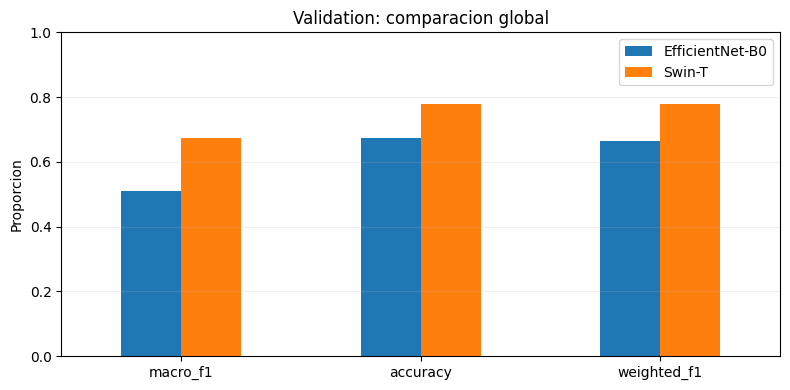

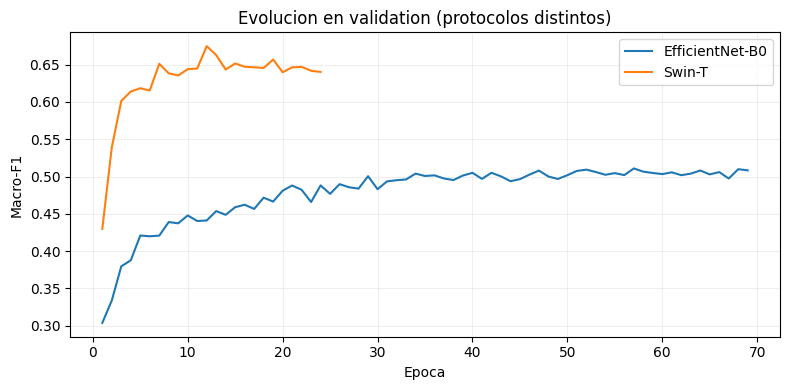

In [2]:
def metricas(y, pred, etiquetas=CLASES):
    precision, recall, f1, _ = precision_recall_fscore_support(y, pred, labels=etiquetas, zero_division=0)
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_precision": precision.mean(), "macro_recall": recall.mean(),
        "macro_f1": f1.mean(),
        "weighted_f1": f1_score(y, pred, labels=etiquetas, average="weighted", zero_division=0),
    }

y = comparacion.real.to_numpy()
p0, p1 = comparacion.pred_b0.to_numpy(), comparacion.pred_swin.to_numpy()
resumen = pd.DataFrame({
    "EfficientNet-B0": metricas(y, p0),
    "Swin-T": metricas(y, p1),
})
resumen["Diferencia (Swin-B0)"] = resumen["Swin-T"] - resumen["EfficientNet-B0"]
display(resumen.round(4))
resumen.to_csv(SALIDA / "metricas_globales.csv")

ax = resumen.loc[["macro_f1", "accuracy", "weighted_f1"], ["EfficientNet-B0", "Swin-T"]].plot.bar(figsize=(8, 4), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("Proporcion"); ax.set_title("Validation: comparacion global")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.savefig(SALIDA / "metricas_globales.png", dpi=150); plt.show()

historias = {
    "EfficientNet-B0": BASE / "C1_EfficientNet_B0/final_v4/metricas.csv",
    "Swin-T": BASE / "C2_Swin_T/final_v1/metricas.csv",
}
if all(ruta.is_file() for ruta in historias.values()):
    fig, ax = plt.subplots(figsize=(8, 4))
    for nombre, ruta in historias.items():
        historial = pd.read_csv(ruta)
        ax.plot(historial["epoca"], historial["macro_f1"], label=nombre)
    ax.set(xlabel="Epoca", ylabel="Macro-F1", title="Evolucion en validation (protocolos distintos)")
    ax.legend(); ax.grid(alpha=0.2)
    plt.tight_layout(); fig.savefig(SALIDA / "curvas_macro_f1.png", dpi=150); plt.show()


##  Especies y corpus

El F1 por fuente se calcula sobre las clases **presentes en esa fuente**, por lo que solo deben compararse los dos modelos *dentro de la misma fuente*.

,codigo,especie,n_validation,f1_b0,f1_swin,delta_f1
7,7,colibri cyanotus,120,0.9750,0.9744,-0.0006
12,12,dendrocolaptes certhia,1,0.0000,0.0000,0.0000
30,30,zonotrichia capensis,261,0.8649,0.8708,0.0059
1,1,arremon brunneinucha,81,0.9506,0.9625,0.0119
25,25,synallaxis azarae,22,0.3056,0.3284,0.0228
2,2,atlapetes schistaceus,46,0.8367,0.8864,0.0496
11,11,cyanocorax violaceus,163,0.8207,0.8810,0.0604
18,18,nyctidromus albicollis,26,0.8070,0.8679,0.0609
0,0,OTHER_SPECIES,1433,0.7530,0.8148,0.0618
15,15,leptotila verreauxi,27,0.7083,0.7755,0.0672


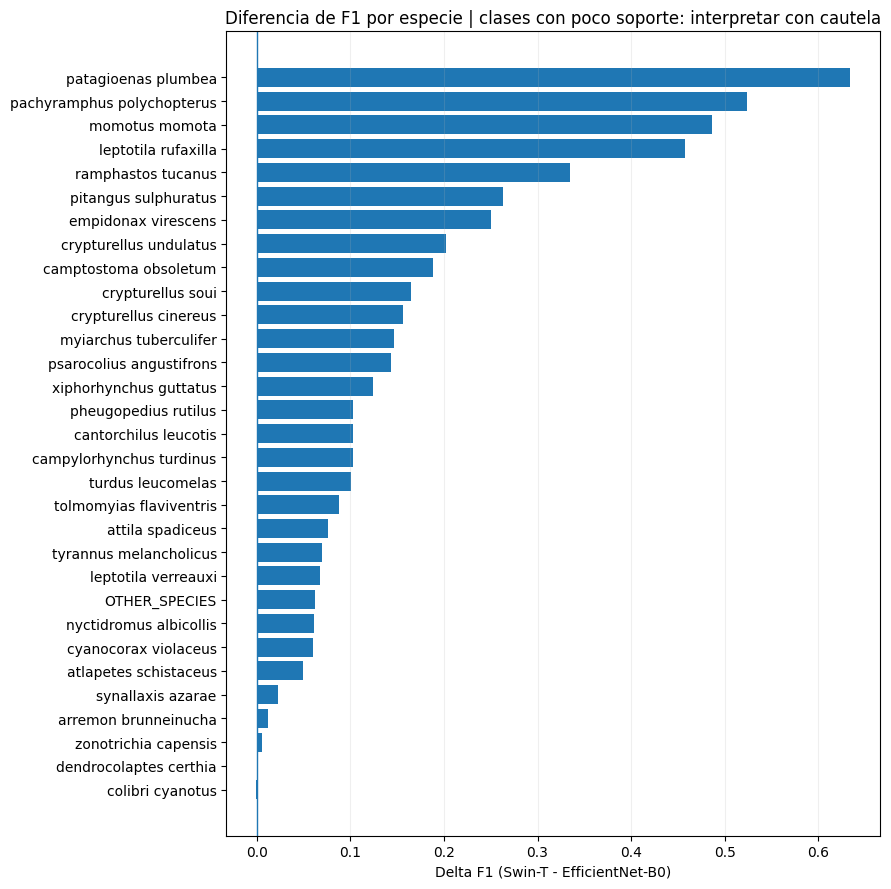

,fuente,eventos,clases_presentes,accuracy_b0,accuracy_swin,macro_f1_b0,macro_f1_swin,delta_macro_f1
0,Col-CR,480,6,0.7875,0.8417,0.4404,0.5775,0.1371
1,Peru,921,13,0.4484,0.6840,0.3177,0.5449,0.2272
2,PteroSet,822,14,0.6922,0.7749,0.4225,0.6002,0.1777
3,WABAD-CO,1385,21,0.7747,0.8217,0.5811,0.6308,0.0497


In [3]:
filas = []
for codigo, especie in NOMBRES.items():
    idx = y == codigo
    f0 = f1_score(y, p0, labels=[codigo], average="macro", zero_division=0)
    f1 = f1_score(y, p1, labels=[codigo], average="macro", zero_division=0)
    filas.append({"codigo": codigo, "especie": especie, "n_validation": int(idx.sum()),
                  "f1_b0": f0, "f1_swin": f1, "delta_f1": f1 - f0})
por_clase = pd.DataFrame(filas).sort_values("delta_f1")
por_clase.to_csv(SALIDA / "metricas_por_clase.csv", index=False)
display(por_clase.round(4))

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(por_clase.especie, por_clase.delta_f1)
ax.axvline(0, linewidth=1); ax.set_xlabel("Delta F1 (Swin-T - EfficientNet-B0)")
ax.set_title("Diferencia de F1 por especie | clases con poco soporte: interpretar con cautela")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout(); fig.savefig(SALIDA / "delta_f1_especies.png", dpi=150); plt.show()

if fuente:
    filas = []
    for origen, sub in comparacion.groupby("fuente"):
        etiquetas = sorted(sub.real.unique())
        m0 = metricas(sub.real, sub.pred_b0, etiquetas)
        m1 = metricas(sub.real, sub.pred_swin, etiquetas)
        filas.append({"fuente": origen, "eventos": len(sub), "clases_presentes": len(etiquetas),
                      "accuracy_b0": m0["accuracy"], "accuracy_swin": m1["accuracy"],
                      "macro_f1_b0": m0["macro_f1"], "macro_f1_swin": m1["macro_f1"],
                      "delta_macro_f1": m1["macro_f1"] - m0["macro_f1"]})
    por_fuente = pd.DataFrame(filas)
    por_fuente.to_csv(SALIDA / "metricas_por_fuente.csv", index=False)
    display(por_fuente.round(4))

## Errores pareados

Se identifican los eventos que Swin-T corrige frente a EfficientNet-B0 y los que empeora.

In [4]:
comparacion["acierto_b0"] = comparacion.real.eq(comparacion.pred_b0)
comparacion["acierto_swin"] = comparacion.real.eq(comparacion.pred_swin)
conteos = pd.Series({
    "Ambos aciertan": int((comparacion.acierto_b0 & comparacion.acierto_swin).sum()),
    "Solo Swin-T acierta": int((~comparacion.acierto_b0 & comparacion.acierto_swin).sum()),
    "Solo EfficientNet-B0 acierta": int((comparacion.acierto_b0 & ~comparacion.acierto_swin).sum()),
    "Ambos fallan": int((~comparacion.acierto_b0 & ~comparacion.acierto_swin).sum()),
}, name="eventos")
display(conteos.to_frame())
assert conteos.sum() == len(comparacion)
discordancias = comparacion.loc[comparacion.acierto_b0.ne(comparacion.acierto_swin)].copy()
discordancias["resultado"] = np.where(discordancias.acierto_swin, "Mejora Swin-T", "Mejora EfficientNet-B0")
discordancias.to_csv(SALIDA / "discordancias_validation.csv", index=False)
display(discordancias[["event_id", "especie", "pred_b0", "pred_swin", "resultado"]].head(12))

,eventos
Ambos aciertan,2230
Solo Swin-T acierta,579
Solo EfficientNet-B0 acierta,203
Ambos fallan,596


,event_id,especie,pred_b0,pred_swin,resultado
0,Col-CR::1392,tyrannus melancholicus,1,28,Mejora Swin-T
16,Col-CR::1447,zonotrichia capensis,30,0,Mejora EfficientNet-B0
17,Col-CR::1448,zonotrichia capensis,30,0,Mejora EfficientNet-B0
22,Col-CR::1478,tyrannus melancholicus,0,28,Mejora Swin-T
23,Col-CR::1479,tyrannus melancholicus,28,0,Mejora EfficientNet-B0
24,Col-CR::1493,tyrannus melancholicus,0,28,Mejora Swin-T
39,Col-CR::1531,tyrannus melancholicus,0,28,Mejora Swin-T
41,Col-CR::1533,tyrannus melancholicus,28,26,Mejora EfficientNet-B0
42,Col-CR::1540,tyrannus melancholicus,26,28,Mejora Swin-T
89,Col-CR::1930,OTHER_SPECIES,30,0,Mejora Swin-T


## 5. Bootstrap pareado por grabación

Se remuestrean **grabaciones completas**, no eventos independientes. El intervalo del 95 % es descriptivo sobre `validation`; las especies escasas y la selección previa de modelos limitan la inferencia.

In [5]:
grupos = list(comparacion.groupby("grabacion", sort=False).indices.values())
assert len(grupos) > 1
rng = np.random.default_rng(42)
B = 1000
cambios = np.empty((B, 2))
for i in range(B):
    muestra = rng.integers(0, len(grupos), len(grupos))
    indices = np.concatenate([grupos[j] for j in muestra])
    yt, e, s = y[indices], p0[indices], p1[indices]
    cambios[i, 0] = f1_score(yt, s, labels=CLASES, average="macro", zero_division=0) - f1_score(yt, e, labels=CLASES, average="macro", zero_division=0)
    cambios[i, 1] = accuracy_score(yt, s) - accuracy_score(yt, e)

ci = pd.DataFrame({
    "metrica": ["macro_f1", "accuracy"],
    "delta_observado": [resumen.loc["macro_f1", "Diferencia (Swin-B0)"], resumen.loc["accuracy", "Diferencia (Swin-B0)"]],
    "ic95_inferior": np.quantile(cambios, 0.025, axis=0),
    "ic95_superior": np.quantile(cambios, 0.975, axis=0),
})
display(ci.round(4))
ci.to_csv(SALIDA / "bootstrap_pareado.csv", index=False)
print("Resultados guardados:", SALIDA)
print("Se utilizo solo validation; test permanece sin evaluar.")

,metrica,delta_observado,ic95_inferior,ic95_superior
0,macro_f1,0.1632,0.0798,0.1831
1,accuracy,0.1042,0.0472,0.1631


Resultados guardados: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C3_Comparacion_v1
Se utilizo solo validation; test permanece sin evaluar.


## Conclusiones

La comparación pareada sobre **3.608 eventos de validación, 128 grabaciones y 31 clases** evidenció un rendimiento superior de Swin-T frente a EfficientNet-B0. Swin-T obtuvo un **Macro-F1 de 0.6747**, frente a 0.5115 de EfficientNet-B0, y una accuracy de 0.7785 frente a 0.6743.

Swin-T mejoró el F1 en 29 de las 31 clases y mostró un rendimiento superior en los cuatro corpus evaluados. En el análisis de errores pareados, Swin-T corrigió 579 eventos que EfficientNet-B0 clasificaba incorrectamente, mientras que ocurrió lo contrario en 203 eventos.

El bootstrap pareado por grabación obtuvo un intervalo del 95 % de **[0.0798, 0.1831]** para la diferencia de Macro-F1, respaldando la consistencia de la mejora observada. No obstante, las clases con pocos ejemplos y las diferencias entre corpus continúan siendo limitaciones relevantes.

**Se selecciona Swin-T como clasificador candidato** para integrar con el detector. Esta decisión se basa en las métricas de validación; todavía deben evaluarse el rendimiento del sistema integrado y su costo computacional. La partición `test` permanece reservada para la evaluación final.